# Học Computer Vision & Image Processing với OpenCV
## Giải thích tiếng Việt, thí nghiệm trực quan và bài tập theo 9 mô-đun

**Nguồn tổ chức chương trình:** [OpenCV University — Detailed Curriculum](https://opencv.org/pdf/Curriculum-Fundamentals-of-Computer-Vision-Image-Processing-OpenCV.pdf), PDF 8 trang.

PDF nguồn là **đề cương**, không phải giáo trình có lời giải. Notebook này dùng thứ tự 9 mô-đun làm khung; các diễn giải, dữ liệu mô phỏng, code, câu hỏi và lời giải là nội dung biên soạn bổ sung. Đây không phải bản dịch nguyên văn hay tài liệu chính thức của OpenCV University.

**Bạn sẽ học được:** ảnh được biểu diễn thế nào, chọn phép xử lý theo vấn đề, hiểu đầu ra của thuật toán, xây dựng một pipeline và nhận ra giới hạn của kết quả.

### Cách học
1. Chọn kernel Python và chạy từ trên xuống. Đọc mục tiêu trước khi chạy mỗi ví dụ.
2. Dự đoán ảnh đầu ra, chạy code, so sánh với dự đoán.
3. Thay đổi một tham số mỗi lần và ghi lại tác động.
4. Làm bài tập trước khi mở phần gợi ý cuối notebook.

Ví dụ chính dùng ảnh tự tạo, không cần tải bộ dữ liệu hoặc bật camera. Các ví dụ GUI, webcam, video và mạng học sâu được đặt trong hàm hoặc điều kiện tùy chọn để **Run All không mở cửa sổ, bật camera hay tự tải mô hình**.

### Bản đồ nội dung
| Mô-đun | Nội dung học | Kết quả thực hành |
|---|---|---|
| [1](#m1) | Ảnh số và thao tác OpenCV | ROI, mask, màu, alpha, annotation |
| [2](#m2) | Video và tương tác | Tạo/đọc video, callback chuột |
| [3](#m3) | Xử lý ảnh nhị phân | Morphology, đếm vùng, contour, blob, QR |
| [4](#m4) | Tăng cường và lọc ảnh | Màu, histogram, nhiễu, gradient, autofocus |
| [5](#m5) | Nhiếp ảnh tính toán | Hough, HDR, inpainting, cloning, chroma key |
| [6](#m6) | Hình học và đặc trưng | Affine, homography, ORB, RANSAC, scanner |
| [7](#m7) | Nhận dạng | GrabCut, HOG + SVM, cascade |
| [8](#m8) | Video và tracking | Optical flow, Kalman, MeanShift, ghép detection |
| [9](#m9) | Học sâu với OpenCV | Blob, NMS, suy luận có điều kiện |

**Kiến thức cần trước:** biến, hàm, vòng lặp Python; slicing NumPy; khái niệm ma trận. Công thức được giải thích ngay tại nơi sử dụng.


## 0. Chuẩn bị môi trường

Cài gói trong **đúng kernel đang sử dụng** nếu chưa có:

```python
%pip install numpy matplotlib "opencv-python>=4.10,<5"
```

Notebook dùng API OpenCV 4.x. Nếu cần CSRT hoặc các tính năng contrib, dùng `opencv-contrib-python>=4.10,<5` **thay cho** `opencv-python`. Không cài đồng thời nhiều biến thể OpenCV trong cùng môi trường vì chúng dùng chung tên `cv2`. Môi trường không có màn hình có thể dùng `opencv-python-headless>=4.10,<5`; các cửa sổ `imshow` sẽ không hoạt động. Khởi động lại kernel sau khi đổi bản OpenCV.

Code dưới đây in phiên bản thực tế, tạo thư mục `cvip_outputs` và định nghĩa hàm hiển thị. Các hình Matplotlib dùng nhãn ngắn tiếng Anh để giảm lỗi font; phần giải thích dùng tiếng Việt.


In [7]:
%matplotlib inline
from pathlib import Path
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

OUT = Path('cvip_outputs') # đường dẫn folder
OUT.mkdir(exist_ok=True) # Tạo folder nếu chưa có
rng = np.random.default_rng(2026) # tạo một random number generator của NumPy
print('Python:', sys.version.split()[0])
print('OpenCV:', cv2.__version__)
print('NumPy:', np.__version__)

def show(items, cols=3, figsize=None):
    # items: [(title, image), ...]; ảnh màu trong notebook luôn là BGR.
    rows = (len(items) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, squeeze=False,
                             figsize=figsize or (5 * cols, 3.5 * rows))
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (title, img) in zip(axes.ravel(), items):
        if img.ndim == 2:
            ax.imshow(img, cmap='gray', vmin=0, vmax=255)
        elif img.shape[2] == 4:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGRA2RGBA))
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

def read_image(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path.resolve())
    img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f'Không giải mã được ảnh: {path}')
    return img

def save_image(path, img):
    path = Path(path)

    if img is None or not isinstance(img, np.ndarray):
        raise ValueError('Ảnh đầu vào không hợp lệ.')

    path.parent.mkdir(parents=True, exist_ok=True)

    ok, buf = cv2.imencode(path.suffix, img)
    if not ok:
        raise ValueError(f'Không mã hóa được ảnh: {path}')

    try:
        buf.tofile(path)
    except OSError as exc:
        raise OSError(f'Không ghi được ảnh: {path}') from exc


Python: 3.15.0
OpenCV: 5.0.0
NumPy: 2.5.4


<a id="m1"></a>
## 1. Getting Started — Hiểu ảnh trước khi xử lý

### 1.1. Xử lý ảnh khác thị giác máy tính thế nào?
- **Xử lý ảnh:** biến đổi hoặc phân tích dữ liệu ảnh, ví dụ khử nhiễu và tăng tương phản.
- **Thị giác máy tính:** suy ra thông tin về cảnh, ví dụ vị trí và số lượng phương tiện.
- Có vùng giao thoa: phân đoạn và trích xuất đặc trưng có thể phục vụ cả hai.

### 1.2. Ảnh được tạo và lưu như thế nào?
Ánh sáng từ cảnh đi qua hệ quang học và được cảm biến đo. Ảnh số xuất hiện sau lấy mẫu theo không gian và lượng tử hóa giá trị đo. Đây là mô tả đơn giản; camera còn có xử lý màu, nhiễu và đáp ứng cảm biến.

Trong mô hình pinhole lý tưởng: $u=f_xX/Z+c_x$, $v=f_yY/Z+c_y$. Vật xa hơn có kích thước chiếu nhỏ hơn. Ảnh thật có méo thấu kính và không nhất thiết tuân theo hoàn toàn mô hình lý tưởng.

Ảnh xám có shape `(H, W)`, ảnh màu `(H, W, 3)`. Với `uint8`, giá trị nằm trong 0–255. OpenCV dùng thứ tự BGR; NumPy truy cập `image[y, x]`. `cv2.resize` nhận kích thước theo `(width, height)`.

### Thí nghiệm 1A: pixel, kênh màu, crop và resize
Quan sát ba hình màu và so sánh các kênh. Vùng đỏ sẽ sáng trong kênh R và tối trong kênh B. ROI lấy bằng slicing có thể là **view**; dùng `.copy()` nếu cần sửa riêng.


shape, dtype: (300, 480, 3) uint8
Pixel trong hình đỏ BGR: [220 100   0]


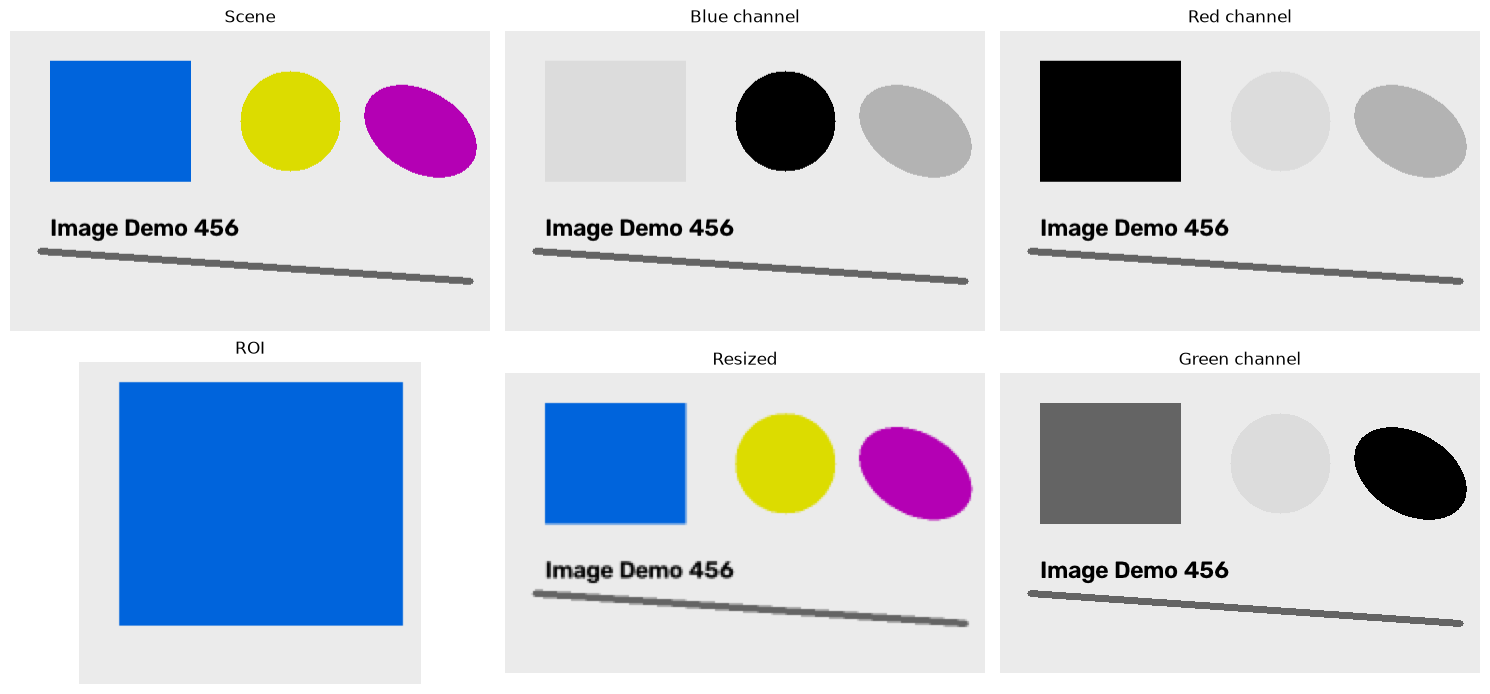

In [15]:
scene = np.full((300, 480, 3), 235, np.uint8)
cv2.rectangle(scene, (40, 30), (180, 150), (220, 100, 0), -1)
cv2.circle(scene, (280, 90), 50, (0, 220, 220), -1)
cv2.ellipse(scene, (410, 100), (60, 40), 30, 0, 360,
            (180, 0, 180), -1)
cv2.line(scene, (30, 220), (460, 250), (100, 100, 100), 5)
cv2.putText(scene, 'Image Demo 456', (40, 205),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8,
            (0, 0, 0), 2)
b, g, r = cv2.split(scene)
roi = scene[20:180, 20:190].copy()
small = cv2.resize(scene, (240, 150), interpolation=cv2.INTER_AREA)
save_image(OUT / 'scene.png', scene)
assert np.array_equal(cv2.merge([b, g, r]), scene)
print('shape, dtype:', scene.shape, scene.dtype)
print('Pixel trong hình đỏ BGR:', scene[70, 60])
show([('Scene', scene), ('Blue channel', b), ('Red channel', r),
      ('ROI', roi), ('Resized', small), ('Green channel', g)])


### 1.3. Độ sáng, tương phản và kiểu dữ liệu
Phép biến đổi tuyến tính: $J=\mathrm{clip}(\alpha I+\beta,0,255)$. $\alpha$ thay đổi tương phản, $\beta$ dịch độ sáng. Chuyển sang số thực trước khi tính; cộng trực tiếp trên `uint8` bằng NumPy có thể quay vòng.

`cv2.add` cộng bão hòa; `cv2.convertScaleAbs` còn lấy trị tuyệt đối nên không hoàn toàn tương đương công thức trên khi có giá trị âm.

### 1.4. Mask và alpha
Mask nhị phân chọn vùng xử lý; alpha cho phép pha trộn mềm:

$$C=\alpha F+(1-\alpha)B$$

Alpha 0 là nền, alpha 1 là lớp phủ. Ví dụ kính dưới đây dùng vị trí thiết kế sẵn để học compositing; chưa tự tìm mắt hay khuôn mặt.


NumPy uint8: 14
OpenCV saturating add: 255


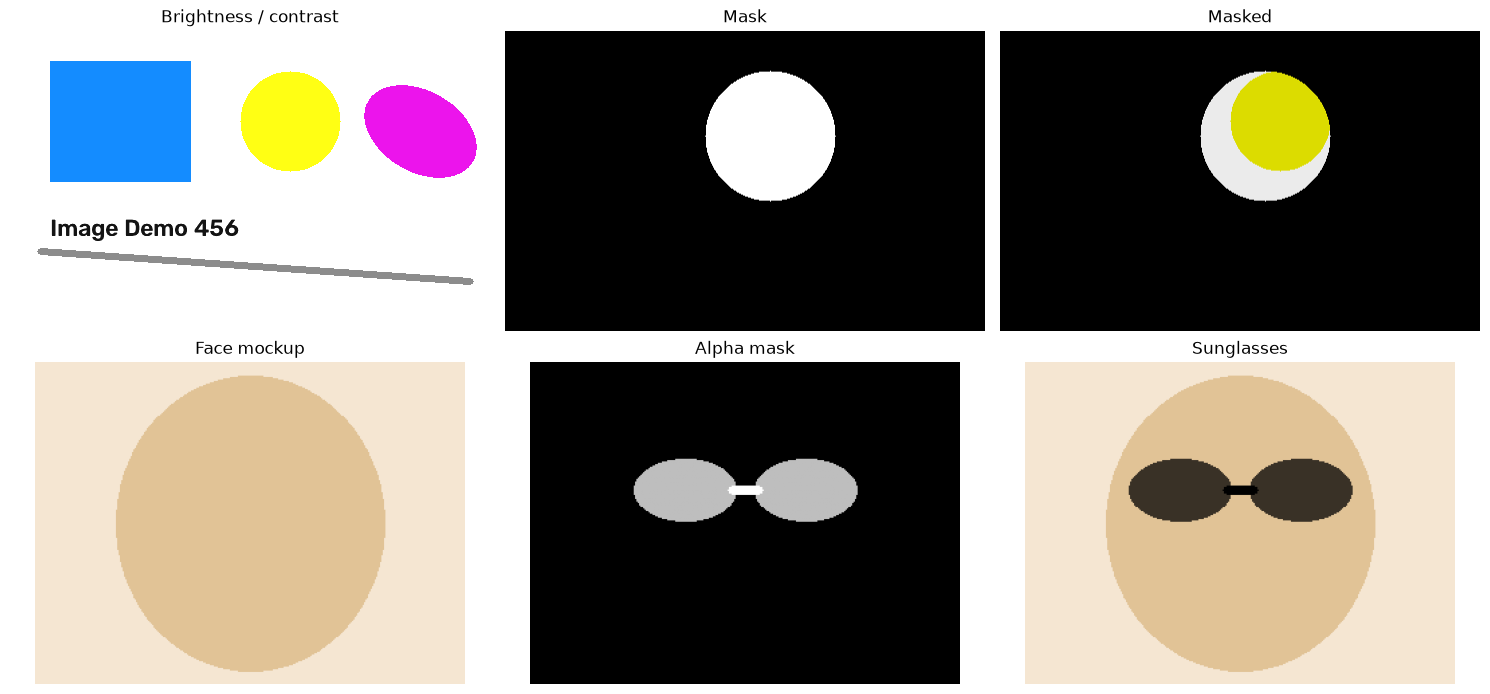

In [16]:
linear = np.clip(scene.astype(np.float32) * 1.2 + 20, 0, 255).astype(np.uint8)
mask = np.zeros(scene.shape[:2], np.uint8)
cv2.circle(mask, (265, 105), 65, 255, -1)
masked = cv2.bitwise_and(scene, scene, mask=mask)

face = np.full((240, 320, 3), (210, 230, 245), np.uint8)
cv2.ellipse(face, (160, 120), (100, 110), 0, 0, 360, (150, 195, 225), -1)
overlay = np.zeros_like(face)
alpha_mask = np.zeros(face.shape[:2], np.uint8)
for center in [(115, 95), (205, 95)]:
    cv2.ellipse(alpha_mask, center, (38, 23), 0, 0, 360, 190, -1)
cv2.line(alpha_mask, (150, 95), (170, 95), 255, 5)
alpha = alpha_mask[..., None].astype(np.float32) / 255
glasses = (alpha * overlay + (1 - alpha) * face).astype(np.uint8)
bgra = np.dstack([overlay, alpha_mask])
save_image(OUT / 'glasses_bgra.png', bgra)
print('NumPy uint8:', (np.array([250], np.uint8) + np.array([20], np.uint8))[0])
print('OpenCV saturating add:', cv2.add(np.array([[250]], np.uint8),
                                          np.array([[20]], np.uint8))[0, 0])
show([('Brightness / contrast', linear), ('Mask', mask), ('Masked', masked),
      ('Face mockup', face), ('Alpha mask', alpha_mask), ('Sunglasses', glasses)])


**Tự kiểm tra mô-đun 1**
1. Vì sao pixel đỏ BGR có giá trị lớn ở vị trí thứ ba?
2. Đổi `alpha_mask` từ 190 sang 80: kính tối hơn hay trong hơn?
3. Tạo mask hình chữ nhật và chỉ tăng độ sáng bên trong mask.
4. Đọc lại `scene.png`; kiểm tra kích thước và sai khác pixel với ảnh gốc. PNG là nén không mất dữ liệu cho ví dụ này; JPEG thường không bảo toàn từng pixel.


<a id="m2"></a>
## 2. Video IO & GUI — Ảnh thay đổi theo thời gian

Video là chuỗi khung hình kèm thông tin thời gian. FPS là số khung hình mỗi giây; codec là phương pháp mã hóa; AVI/MP4 là container, không phải codec. Với FPS cố định, $t=n/\mathrm{FPS}$; video tốc độ khung hình biến thiên cần chú ý timestamp.

### Thí nghiệm 2A: ghi và đọc video tự tạo
Tạo 30 khung ở 15 FPS, dự kiến dài khoảng 2 giây. Cần `isOpened()`, kiểm tra `read()` và luôn `release()`. Codec có thể khác nhau giữa máy nên ví dụ bỏ qua có thông báo nếu encoder không mở được.


Read 30 frames, FPS=15.0


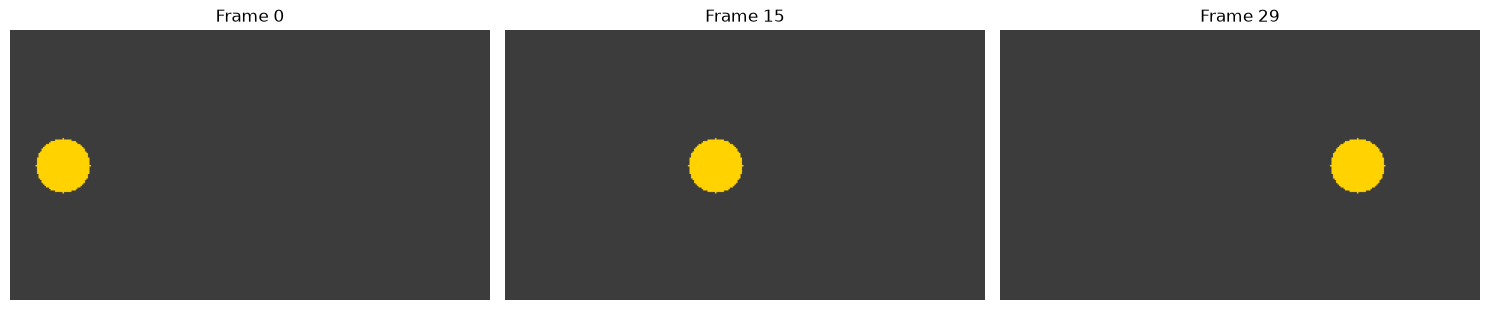

In [20]:
frames = []
for t in range(30):
    frame = np.full((180, 320, 3), 60, np.uint8)
    cv2.circle(frame, (35 + 7 * t, 90), 18, (0, 210, 255), -1)
    frames.append(frame)
video_path = OUT / 'moving_ball.avi'
writer = cv2.VideoWriter(str(video_path), cv2.VideoWriter_fourcc(*'MJPG'),
                         15.0, (320, 180))
written = writer.isOpened()
try:
    if written:
        for frame in frames:
            writer.write(frame)
finally:
    writer.release()
if written:
    cap = cv2.VideoCapture(str(video_path))
    count = 0
    try:
        fps_read = cap.get(cv2.CAP_PROP_FPS)
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            count += 1
    finally:
        cap.release()
    print(f'Read {count} frames, FPS={fps_read:.1f}')
else:
    print('Codec MJPG không khả dụng; vẫn có frames trong bộ nhớ để học.')
show([('Frame 0', frames[0]), ('Frame 15', frames[15]), ('Frame 29', frames[29])])


### 2.2. Callback, chuột và bàn phím — ví dụ tùy chọn
Callback là hàm được gọi khi sự kiện xảy ra. `setMouseCallback` đăng ký hàm xử lý chuột; `waitKey` vừa nhận phím vừa giúp HighGUI xử lý sự kiện.

Hàm dưới đây chỉ được **định nghĩa**, không tự chạy. Dùng bản OpenCV có GUI trên máy cục bộ; gọi `annotate_with_mouse(scene)` trong ô riêng. Nhấp trái để đánh dấu; nhấn **q** hoặc **Esc** để thoát. Trong Jupyter từ xa/headless, dùng Matplotlib hoặc widget thay HighGUI.


In [21]:
def annotate_with_mouse(image):
    canvas = image.copy()
    def on_mouse(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN:
            cv2.circle(canvas, (x, y), 5, (0, 0, 255), -1)
    try:
        cv2.namedWindow('Annotation')
        cv2.setMouseCallback('Annotation', on_mouse)
        while True:
            cv2.imshow('Annotation', canvas)
            if cv2.waitKey(20) & 0xFF in (ord('q'), 27):
                break
    finally:
        cv2.destroyAllWindows()
    return canvas

# Tùy chọn: annotated = annotate_with_mouse(scene)


**Bài tập:** sửa callback để nhấn-kéo-thả vẽ hộp chữ nhật; thêm phím `s` để lưu ảnh. Với webcam, nguồn là `VideoCapture(0)` nhưng chỉ bật khi chủ động thực hiện; phải kiểm tra thiết bị và giải phóng camera trong `finally`.


<a id="m3"></a>
## 3. Binary Image Processing — Từ pixel đến vùng đối tượng

### 3.1. Thresholding
Với ngưỡng $T$, pixel được gán 0 hoặc 255 theo điều kiện $I>T$. Ngưỡng cố định phù hợp khi ánh sáng ổn định; Otsu chọn ngưỡng từ histogram bằng tiêu chí phương sai giữa hai lớp; ngưỡng thích nghi tính theo vùng.

### 3.2. Morphology
Giả sử đối tượng là trắng trên nền đen:
- Erosion thu hẹp vùng trắng; dilation mở rộng vùng trắng.
- Opening = erosion rồi dilation: thường loại chấm trắng nhỏ.
- Closing = dilation rồi erosion: thường lấp lỗ và khe nhỏ.

Kernel xác định vùng lân cận và tỉ lệ cấu trúc bị tác động. Kernel lớn không mặc nhiên tốt hơn.

### Thí nghiệm 3A: đếm các đồng xu mô phỏng
Dữ liệu có 4 đĩa tách rời, thêm nhiễu điểm. Đây là minh họa đếm vùng, không xác nhận vật liệu hoặc mệnh giá đồng xu.


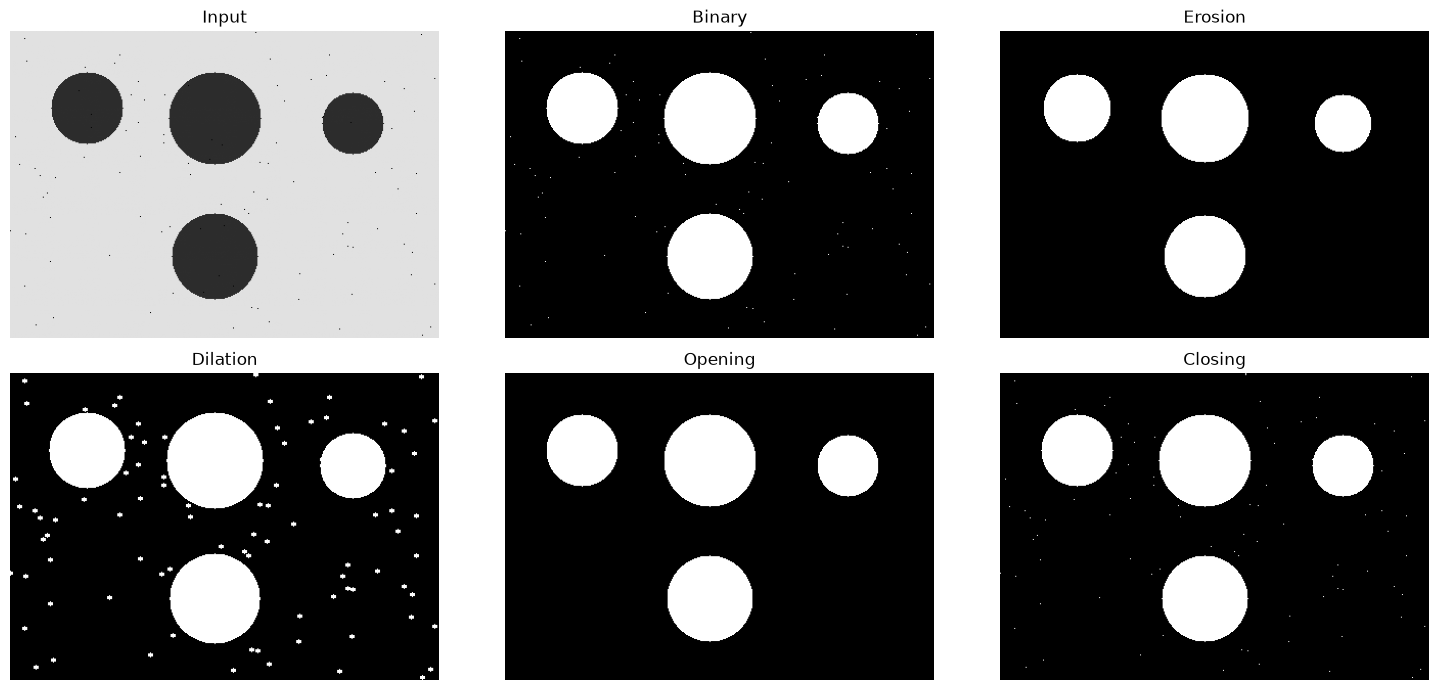

In [22]:
coins = np.full((300, 420), 225, np.uint8)
for x, y, radius in [(75, 75, 35), (200, 85, 45), (335, 90, 30), (200, 220, 42)]:
    cv2.circle(coins, (x, y), radius, 45, -1)
coins_noisy = coins.copy()
yy = rng.integers(0, 300, 100)
xx = rng.integers(0, 420, 100)
coins_noisy[yy, xx] = 0
_, binary = cv2.threshold(coins_noisy, 0, 255,
                          cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k)
eroded = cv2.erode(binary, k)
dilated = cv2.dilate(binary, k)
closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, k)
show([('Input', coins_noisy), ('Binary', binary), ('Erosion', eroded),
      ('Dilation', dilated), ('Opening', opened), ('Closing', closed)])


### 3.3. Connected components, contour và blob khác nhau ra sao?
- **Connected components:** gán nhãn mỗi vùng liên thông; nhãn 0 là nền. Connectivity 4 chỉ xét cạnh, 8 xét cả đường chéo.
- **Contour:** biểu diễn đường bao, tiện tính chu vi và hình dạng; có thể lấy quan hệ vùng lồng nhau.
- **Blob detector:** tìm vùng thỏa bộ điều kiện như diện tích, độ tròn; không phải mô hình nhận diện ngữ nghĩa.

Độ tròn $C=4\pi A/P^2$, với diện tích $A$, chu vi $P$. Giá trị gần 1 gợi ý hình tròn, nhưng bị ảnh hưởng bởi rời rạc hóa.

**Quan sát:** diện tích contour và số pixel vùng liên thông có thể khác vì định nghĩa đo khác nhau. Khi vật thể chạm nhau, đếm component/contour có thể gộp nhiều vật thành một.


Vùng 1: area=5404, circularity=0.893
Vùng 2: area=2730, circularity=0.892
Vùng 3: area=6232, circularity=0.899
Vùng 4: area=3752, circularity=0.898
Components, contours, blobs: 4 4 4


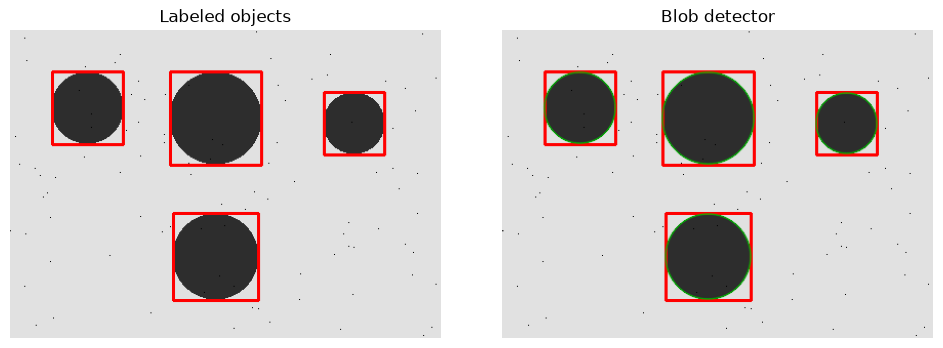

In [23]:
n_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(opened, 8)
contours, hierarchy = cv2.findContours(opened, cv2.RETR_EXTERNAL,
                                      cv2.CHAIN_APPROX_SIMPLE)
valid = [c for c in contours if cv2.contourArea(c) > 500]
coin_result = cv2.cvtColor(coins_noisy, cv2.COLOR_GRAY2BGR)
for i, contour in enumerate(valid, 1):
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)
    circularity = 4 * np.pi * area / max(perimeter**2, 1e-9)
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(coin_result, (x, y), (x + w, y + h), (0, 0, 255), 2)
    print(f'Vùng {i}: area={area:.0f}, circularity={circularity:.3f}')
params = cv2.SimpleBlobDetector_Params()
params.filterByArea = True
params.minArea, params.maxArea = 500, 10000
params.filterByColor = True
params.blobColor = 255
params.filterByCircularity = False
params.filterByConvexity = False
params.filterByInertia = False
keypoints = cv2.SimpleBlobDetector_create(params).detect(opened)
blob_view = cv2.drawKeypoints(coin_result, keypoints, None, (0, 180, 0),
                             cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
print('Components, contours, blobs:', n_labels - 1, len(valid), len(keypoints))
assert len(valid) == 4, 'Ảnh mô phỏng phải có 4 vùng lớn tách rời.'
show([('Labeled objects', coin_result), ('Blob detector', blob_view)], cols=2)


### 3.4. QR detector — bài thực hành mở rộng
QR có cấu trúc mã hóa và dấu định vị; không nên coi mọi nhóm hình vuông là QR. OpenCV có bộ phát hiện/giải mã sẵn. Ví dụ sau chỉ chạy nếu bạn đặt `qr.png` cùng notebook. Chuỗi rỗng có thể do không tìm được mã hoặc không giải mã được; không chứng minh ảnh chắc chắn không chứa QR.


Nội dung QR: 'https://gravatar.com/ehastings1'


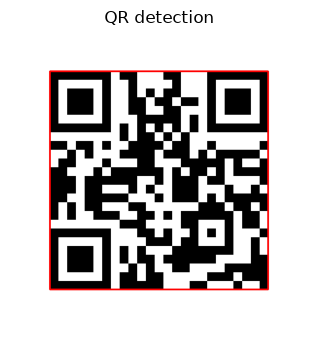

In [25]:
qr_path = Path('qr.png')
if qr_path.is_file():
    qr_image = read_image(qr_path)
    text, points, straight = cv2.QRCodeDetector().detectAndDecode(qr_image)
    print('Nội dung QR:', repr(text))
    if points is not None:
        cv2.polylines(qr_image, [np.int32(points).reshape(-1, 2)],
                      True, (0, 0, 255), 2)
    show([('QR detection', qr_image)], cols=1)
else:
    print('Tùy chọn: thêm qr.png để thử QRCodeDetector.')


**Bài tập mô-đun 3:** cho hai đồng xu chạm nhau và ghi số đếm; thử kernel 3, 7, 15; giải thích vì sao opening có thể xóa vật thể nhỏ. Thêm một lỗ đen vào vật thể trắng để so sánh opening và closing. Muốn tách vật thể chạm nhau có thể nghiên cứu distance transform + watershed; morphology đơn thuần không luôn giải quyết được.


<a id="m4"></a>
## 4. Image Enhancement & Filtering — Chọn phép lọc theo vấn đề

### 4.1. Không gian màu và màu chủ đạo
RGB/BGR trộn thông tin màu và sáng. HSV tách Hue, Saturation, Value nên thuận tiện chọn vùng theo màu. Với HSV `uint8` mặc định của OpenCV, H thường nằm 0–179; S,V nằm 0–255. Đỏ nằm gần cả hai đầu trục Hue nên thường cần hai khoảng.

Màu chủ đạo có thể ước lượng từ histogram hoặc clustering; kết quả phụ thuộc ảnh, mask và số cụm. Nếu nền chiếm phần lớn, màu nền có thể trở thành màu chủ đạo.

### Thí nghiệm 4A: tách màu đỏ, giảm bão hòa và clustering


Dominant BGR: [235 235 235]


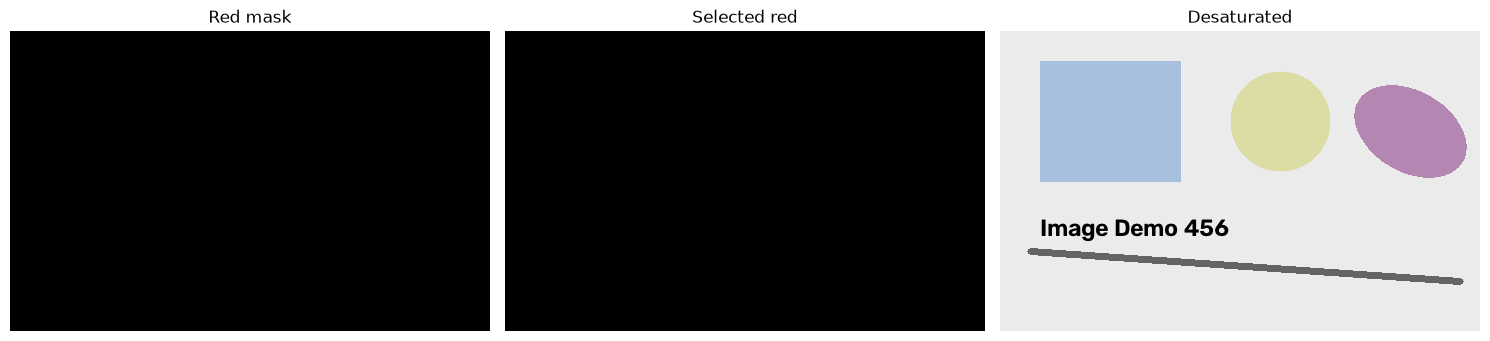

In [26]:
hsv = cv2.cvtColor(scene, cv2.COLOR_BGR2HSV)
red_mask = cv2.bitwise_or(cv2.inRange(hsv, (0, 100, 80), (10, 255, 255)),
                          cv2.inRange(hsv, (170, 100, 80), (179, 255, 255)))
desaturated = hsv.copy()
desaturated[..., 1] = (desaturated[..., 1] * 0.25).astype(np.uint8)
desaturated = cv2.cvtColor(desaturated, cv2.COLOR_HSV2BGR)
pixels = scene.reshape(-1, 3)[::10].astype(np.float32)
cv2.setRNGSeed(42)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.2)
_, cluster_ids, centers = cv2.kmeans(pixels, 4, None, criteria, 3,
                                    cv2.KMEANS_PP_CENTERS)
counts = np.bincount(cluster_ids.ravel(), minlength=4)
print('Dominant BGR:', centers[counts.argmax()].round().astype(int))
show([('Red mask', red_mask), ('Selected red', cv2.bitwise_and(scene, scene, mask=red_mask)),
      ('Desaturated', desaturated)])


### 4.2. Histogram equalization, CLAHE và curves
Histogram đếm tần suất mức sáng. Equalization dùng phân bố tích lũy để phân bố lại mức sáng; không khôi phục được chi tiết đã mất. CLAHE làm tương phản cục bộ và giới hạn khuếch đại để giảm tác động nhiễu.

Với ảnh màu, có thể xử lý kênh độ sáng thay vì equalize độc lập B,G,R để giảm biến đổi màu ngoài ý muốn. Curve là ánh xạ $J=LUT[I]$; ví dụ $J=255(I/255)^\gamma$. Với quy ước này, $\gamma<1$ làm sáng các mức trung gian.


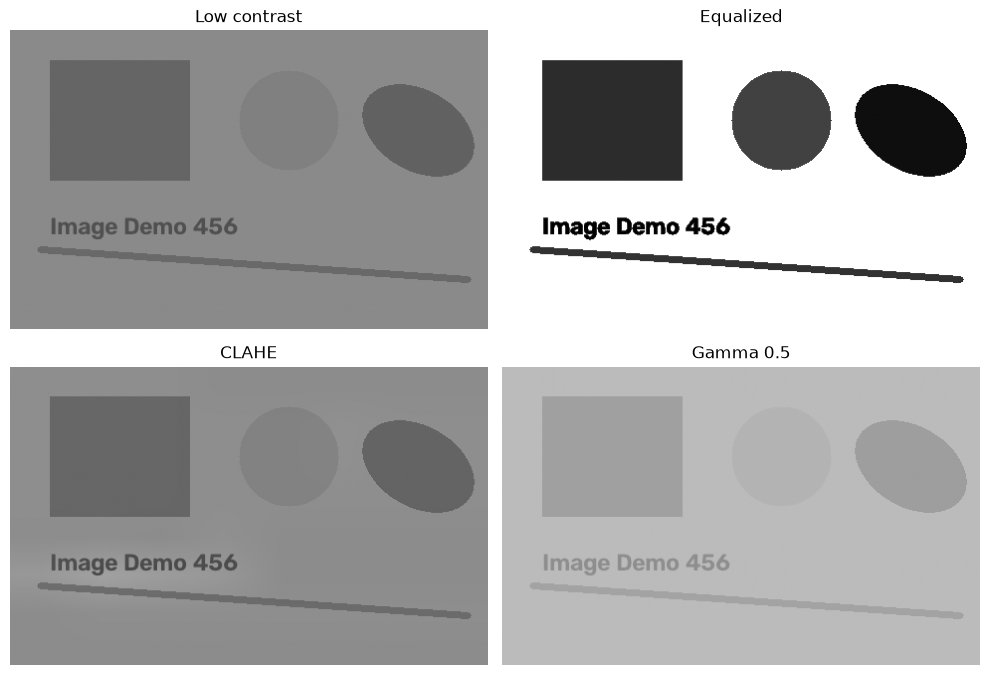

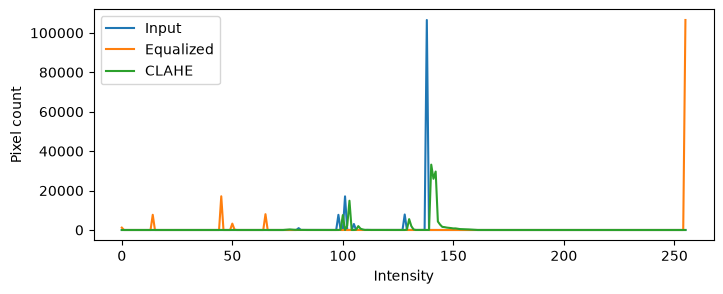

In [28]:
gray_scene = cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY)
low_contrast = (gray_scene.astype(np.float32) * 0.25 + 80).astype(np.uint8)
equalized = cv2.equalizeHist(low_contrast)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(low_contrast)
gamma = 0.5
lut = np.clip(255 * (np.arange(256) / 255.0)**gamma, 0, 255).astype(np.uint8)
curved = cv2.LUT(low_contrast, lut)
show([('Low contrast', low_contrast), ('Equalized', equalized),
      ('CLAHE', clahe), ('Gamma 0.5', curved)], cols=2)
plt.figure(figsize=(8, 3))
for title, img in [('Input', low_contrast), ('Equalized', equalized), ('CLAHE', clahe)]:
    hist = cv2.calcHist([img], [0], None, [256], [0, 256])
    plt.plot(hist, label=title)
plt.xlabel('Intensity'); plt.ylabel('Pixel count'); plt.legend(); plt.show()


### 4.3. Convolution và các bộ lọc làm mượt
Tích chập lý thuyết có lật kernel; `cv2.filter2D` thực hiện **correlation** (không lật kernel). Với kernel đối xứng như trung bình hoặc Gaussian, hai kết quả trùng nhau. Với kernel bất đối xứng cần chú ý quy ước.

| Bộ lọc | Ý tưởng | Khi thử | Giới hạn |
|---|---|---|---|
| Box | Trung bình đều | Mượt nhanh | Mờ biên |
| Gaussian | Trọng số giảm theo khoảng cách | Nhiễu dạng Gaussian, trước gradient | Vẫn mờ biên |
| Median | Trung vị lân cận | Muối tiêu | Mất chi tiết nhỏ |
| Bilateral | Trọng số theo khoảng cách và mức sáng | Mượt nhưng giữ biên | Chậm, phụ thuộc tham số |

### Thí nghiệm 4B: cùng một ảnh, hai loại nhiễu
MSE so sánh với ảnh sạch đã biết. Không chỉ xem MSE: ảnh mượt quá mức có thể mất biên hữu ích cho nhiệm vụ sau đó.


In [ ]:
clean = gray_scene
gaussian_noise = np.clip(clean.astype(np.float32) + rng.normal(0, 18, clean.shape),
                          0, 255).astype(np.uint8)
salt_pepper = clean.copy()
u = rng.random(clean.shape)
salt_pepper[u < 0.025] = 0
salt_pepper[u > 0.975] = 255
kernel = np.ones((5, 5), np.float32) / 25
filtered = {
    'Box': cv2.filter2D(salt_pepper, -1, kernel),
    'Gaussian': cv2.GaussianBlur(salt_pepper, (5, 5), 1.2),
    'Median': cv2.medianBlur(salt_pepper, 5),
    'Bilateral': cv2.bilateralFilter(salt_pepper, 7, 50, 50),
}
def mse(a, b):
    return float(np.mean((a.astype(np.float32) - b.astype(np.float32))**2))
for name, img in filtered.items():
    print(name, 'MSE:', round(mse(clean, img), 2))
show([('Clean', clean), ('Salt / pepper', salt_pepper)] + list(filtered.items()))


### 4.4. Gradient, Canny và sharpening
Gradient bậc nhất đo thay đổi cường độ theo hướng x,y. Sobel ước lượng $G_x,G_y$; độ lớn $G=\sqrt{G_x^2+G_y^2}$. Laplacian dùng đạo hàm bậc hai. Đạo hàm nhạy với nhiễu nên thường làm mượt trước.

Canny kết hợp gradient, loại cực đại không phù hợp và liên kết biên theo hai ngưỡng. Biên ảnh có thể do bóng hoặc họa tiết; không đồng nghĩa với ranh giới đối tượng.

Unsharp mask: $J=I+k(I-\mathrm{blur}(I))$. Sharpening không khôi phục được mọi chi tiết đã mất và có thể tăng nhiễu.

**Autofocus minh họa:** variance of Laplacian là một thước đo độ sắc nét thường dùng. So sánh đáng tin hơn khi cảnh, kích thước, phơi sáng và nhiễu tương tự. Đây chưa phải hệ thống điều khiển motor lấy nét.


In [ ]:
smooth = cv2.GaussianBlur(gaussian_noise, (5, 5), 1.2)
gx = cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3)
magnitude = cv2.normalize(cv2.magnitude(gx, gy), None, 0, 255,
                          cv2.NORM_MINMAX).astype(np.uint8)
edges = cv2.Canny(smooth, 60, 150)
sharp = np.clip(clean.astype(np.float32) + 1.5 * (
    clean.astype(np.float32) - cv2.GaussianBlur(clean, (5, 5), 1)), 0, 255).astype(np.uint8)
sigmas = [0, 1, 2, 4]
focus_scores = []
for sigma in sigmas:
    img = clean if sigma == 0 else cv2.GaussianBlur(clean, (0, 0), sigma)
    focus_scores.append(cv2.Laplacian(img, cv2.CV_64F).var())
print('Sigma / focus score:', list(zip(sigmas, np.round(focus_scores, 2))))
show([('Noisy', gaussian_noise), ('Smoothed', smooth), ('Gradient', magnitude),
      ('Canny', edges), ('Sharpened', sharp)])
plt.plot(sigmas, focus_scores, 'o-'); plt.xlabel('Blur sigma')
plt.ylabel('Variance of Laplacian'); plt.show()


**Bài tập mô-đun 4:** chạy bốn bộ lọc trên `gaussian_noise`, so sánh với trường hợp muối tiêu; tăng Canny low/high threshold; thêm nhiễu mạnh rồi đo focus score để thấy độ sắc nét có thể bị đánh giá sai. Khi báo cáo, giải thích lý do chọn bộ lọc thay vì chỉ đưa ảnh kết quả.


<a id="m5"></a>
## 5. Advanced Image Processing & Computational Photography

### 5.1. Hough: tìm hình có mô hình hình học
Đường thẳng có thể tham số hóa $\rho=x\cos\theta+y\sin\theta$. Điểm biên bỏ phiếu trong không gian tham số; cực đại gợi ý đường thẳng. `HoughLinesP` trả về đoạn thẳng. Hough circle tìm cấu trúc tròn nhưng cần giới hạn bán kính và khoảng cách tâm.

Thích hợp: vạch đường, đường kẻ tài liệu, vật tròn. Không đảm bảo mọi đường/hình tròn tìm được đều là đối tượng cần tìm.


In [ ]:
geometry = np.zeros((280, 400), np.uint8)
cv2.line(geometry, (20, 30), (370, 80), 255, 3)
cv2.line(geometry, (30, 245), (170, 130), 255, 3)
cv2.circle(geometry, (290, 185), 50, 255, 3)
geometry_edges = cv2.Canny(geometry, 50, 150)
lines = cv2.HoughLinesP(geometry_edges, 1, np.pi / 180, 45,
                        minLineLength=70, maxLineGap=10)
circles = cv2.HoughCircles(cv2.GaussianBlur(geometry, (5, 5), 1),
    cv2.HOUGH_GRADIENT, dp=1.2, minDist=80, param1=100, param2=25,
    minRadius=35, maxRadius=65)
hough_view = cv2.cvtColor(geometry, cv2.COLOR_GRAY2BGR)
if lines is not None:
    for x1, y1, x2, y2 in np.asarray(lines).reshape(-1, 4):
        cv2.line(hough_view, (x1, y1), (x2, y2), (0, 0, 255), 2)
if circles is not None:
    for x, y, radius in np.round(np.asarray(circles).reshape(-1, 3)).astype(int):
        cv2.circle(hough_view, (x, y), radius, (0, 255, 0), 2)
print('Line segments:', 0 if lines is None else len(lines))
print('Circles:', 0 if circles is None else np.asarray(circles).reshape(-1, 3).shape[0])
show([('Shapes', geometry), ('Edges', geometry_edges), ('Hough results', hough_view)])


### 5.2. HDR và exposure fusion
Dynamic range là khoảng giữa tín hiệu tối và sáng có thể ghi nhận. HDR thường kết hợp ảnh nhiều phơi sáng để ước lượng thông tin dải rộng, rồi tone-map để hiển thị.

**Phân biệt:** exposure fusion chọn/kết hợp vùng hữu ích từ các ảnh phơi sáng; đầu ra đẹp hơn không đồng nghĩa đã tái dựng bức xạ HDR vật lý. Ví dụ dưới đây dùng `MergeMertens` trên các ảnh tổng hợp để học fusion. Các ảnh được tạo từ một ảnh gốc nên không tạo thêm thông tin cảnh mới.

Với dữ liệu HDR thực: chụp cùng cảnh ở nhiều thời gian phơi sáng, căn chỉnh chuyển động, xử lý đáp ứng camera (ví dụ Debevec) rồi tone-map. Vật thể chuyển động có thể gây ghosting.

### 5.3. Inpainting và seamless cloning
Inpainting ước lượng vùng bị che từ lân cận; mask khác 0 chỉ vùng cần sửa. Seamless cloning dùng thông tin gradient để hòa trộn nguồn vào đích. Không phương pháp nào bảo đảm phục hồi đúng nội dung thật đã mất.


In [ ]:
exposures = [np.clip(scene.astype(np.float32) * factor, 0, 255).astype(np.uint8)
             for factor in [0.45, 1.0, 1.65]]
fused_float = cv2.createMergeMertens().process(exposures)
fused = np.clip(fused_float * 255, 0, 255).astype(np.uint8)
damage_mask = np.zeros(scene.shape[:2], np.uint8)
cv2.line(damage_mask, (30, 55), (440, 190), 255, 5)
damaged = scene.copy()
damaged[damage_mask > 0] = 255
repaired = cv2.inpaint(damaged, damage_mask, 3, cv2.INPAINT_TELEA)
patch = np.full((80, 80, 3), (100, 180, 200), np.uint8)
cv2.circle(patch, (40, 40), 20, (20, 60, 160), -1)
clone_mask = np.zeros((80, 80), np.uint8)
cv2.circle(clone_mask, (40, 40), 30, 255, -1)
cloned = cv2.seamlessClone(patch, scene.copy(), clone_mask,
                          (260, 110), cv2.NORMAL_CLONE)
show([('Underexposed', exposures[0]), ('Overexposed', exposures[2]),
      ('Exposure fusion', fused), ('Damaged', damaged),
      ('Inpainted', repaired), ('Seamless clone', cloned)])


### 5.4. Chroma key — thay nền xanh
Chọn mask theo màu nền rồi ghép foreground/background. Với ví dụ tổng hợp, màu xanh tách rất rõ. Ảnh thật cần xử lý biên tóc, bóng đổ và green spill; ngưỡng HSV đơn giản có thể làm mất cả quần áo xanh.


In [ ]:
green_screen = np.full((240, 320, 3), (0, 220, 0), np.uint8)
cv2.circle(green_screen, (160, 85), 45, (130, 175, 220), -1)
cv2.rectangle(green_screen, (105, 125), (215, 235), (180, 60, 50), -1)
key_hsv = cv2.cvtColor(green_screen, cv2.COLOR_BGR2HSV)
background_mask = cv2.inRange(key_hsv, (35, 80, 60), (85, 255, 255))
new_background = cv2.resize(scene, (320, 240))
keyed = np.where(background_mask[..., None] > 0, new_background, green_screen)
show([('Green screen', green_screen), ('Background mask', background_mask),
      ('Replaced background', keyed)])


**Mini-project 1:** làm bộ lọc ảnh có ba chế độ: gamma, tăng sắc nét và giảm bão hòa. Báo cáo ảnh gốc/kết quả cùng tham số. Mở rộng xóa vết nhỏ bằng inpainting hoặc chroma key. Không gọi exposure fusion là HDR tái dựng nếu chưa có dữ liệu/phương pháp phù hợp.


<a id="m6"></a>
## 6. Geometric Transforms & Image Features

### 6.1. Affine và homography
Affine dùng ma trận $2\times3$, bảo toàn tính song song; ba cặp điểm không thẳng hàng xác định một phép affine tổng quát. Homography dùng ma trận $3\times3$ theo tọa độ thuần nhất:

$$s\begin{bmatrix}u\v\1\end{bmatrix}=H\begin{bmatrix}x\y\1\end{bmatrix}$$

Cần ít nhất bốn cặp điểm ở cấu hình phù hợp. Sau biến đổi cần chia cho tọa độ thứ ba. Homography phù hợp cảnh phẳng hoặc một số chuyển động camera như quay quanh tâm quang học; không biểu diễn chính xác mọi cảnh 3D có parallax.

### Thí nghiệm 6A: scanner với bốn góc đã biết
Tạo một trang giấy, đặt vào ảnh nghiêng rồi chỉnh lại. Việc **tự tìm bốn góc** chưa nằm trong ví dụ này; sẽ là phần mở rộng. Thứ tự góc phải tương ứng: trên trái, trên phải, dưới phải, dưới trái.


In [ ]:
document = np.full((280, 200, 3), 250, np.uint8)
cv2.rectangle(document, (5, 5), (194, 274), (0, 0, 0), 2)
cv2.putText(document, 'CV NOTES', (12, 40), cv2.FONT_HERSHEY_SIMPLEX,
            0.7, (0, 0, 0), 2)
for y in range(65, 255, 22):
    cv2.line(document, (15, y), (180, y), (60, 60, 60), 2)
src_corners = np.float32([[0, 0], [199, 0], [199, 279], [0, 279]])
dst_corners = np.float32([[90, 35], [310, 70], [335, 320], [45, 295]])
H_doc = cv2.getPerspectiveTransform(src_corners, dst_corners)
photographed = cv2.warpPerspective(document, H_doc, (400, 360), borderValue=(55, 55, 55))
H_rectify = cv2.getPerspectiveTransform(dst_corners, src_corners)
scanned = cv2.warpPerspective(photographed, H_rectify, (200, 280))
rotation = cv2.getRotationMatrix2D((240, 150), 20, 0.8)
rotated = cv2.warpAffine(scene, rotation, (480, 300))
show([('Document mockup', document), ('Perspective photo', photographed),
      ('Rectified', scanned), ('Affine rotation', rotated)], cols=2)


### 6.2. ORB, matching và RANSAC
Keypoint là vị trí đặc trưng; descriptor mô tả vùng quanh vị trí đó. ORB tạo descriptor nhị phân, thường ghép bằng Hamming distance. Không dùng L2 một cách mặc định cho descriptor nhị phân.

Nearest-neighbor matching luôn có thể tìm một ứng viên dù nó sai. Ratio test so khoảng cách hai ứng viên gần nhất; RANSAC tìm mô hình nhất quán với nhiều cặp và loại outlier. Ngưỡng ratio/reprojection cần được kiểm tra thực nghiệm.

### Thí nghiệm 6B: biết biến đổi thật để đo sai số
Ảnh texture được tạo xác định. Từ match ước lượng homography, sau đó so tọa độ bốn góc với biến đổi thật. Đây là kiểm tra hình học có ground truth, mạnh hơn việc chỉ nhìn các đường nối đẹp.


In [ ]:
texture_rng = np.random.default_rng(7)
texture = np.full((320, 440), 220, np.uint8)
for i in range(180):
    x, y = texture_rng.integers([15, 15], [425, 305])
    cv2.circle(texture, (int(x), int(y)), int(texture_rng.integers(2, 8)),
               int(texture_rng.integers(0, 160)), -1)
cv2.putText(texture, 'FEATURE MATCH 2026', (20, 160),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, 0, 2)
H_true = np.array([[0.98, -0.04, 16], [0.03, 0.98, 10],
                   [0.00008, -0.00005, 1]], np.float64)
transformed = cv2.warpPerspective(texture, H_true, (440, 320), borderValue=220)
orb = cv2.ORB_create(nfeatures=1200)
kp1, des1 = orb.detectAndCompute(texture, None)
kp2, des2 = orb.detectAndCompute(transformed, None)
good, H_est, inlier_mask = [], None, None
if des1 is not None and des2 is not None:
    pairs = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(des1, des2, k=2)
    good = [pair[0] for pair in pairs if len(pair) == 2 and
            pair[0].distance < 0.75 * pair[1].distance]
    if len(good) >= 4:
        p1 = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        p2 = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        H_est, inlier_mask = cv2.findHomography(p1, p2, cv2.RANSAC, 3.0)
print('Keypoints:', len(kp1), len(kp2), 'Good matches:', len(good))
if H_est is not None:
    corners = np.float32([[0, 0], [439, 0], [439, 319], [0, 319]]).reshape(-1, 1, 2)
    truth = cv2.perspectiveTransform(corners, H_true)
    estimate = cv2.perspectiveTransform(corners, H_est)
    corner_error = np.linalg.norm(truth - estimate, axis=2).mean()
    print('RANSAC inliers:', int(inlier_mask.sum()))
    print('Mean corner error (pixels):', round(float(corner_error), 3))
    aligned = cv2.warpPerspective(transformed, np.linalg.inv(H_est), (440, 320))
    show([('Reference', texture), ('Warped', transformed), ('Aligned back', aligned)])
else:
    print('Không đủ match hình học tốt; thử thay texture/tham số ORB.')
match_view = cv2.drawMatches(texture, kp1, transformed, kp2, good[:35], None,
                             flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show([('ORB correspondences', match_view)], cols=1, figsize=(13, 5))


### 6.3. Panorama: ghép đúng vị trí chưa đủ
Panorama cần ảnh có phần chồng lấn, tìm match, ước lượng biến đổi, chọn canvas, warp, xử lý đường nối và hòa trộn. Thay đổi phơi sáng, parallax và vật thể chuyển động gây lỗi. `Stitcher` cung cấp pipeline mức cao nhưng vẫn có thể thất bại.

Ví dụ dưới đây tạo hai crop có overlap lớn từ ảnh texture. Nếu không ghép được, trạng thái lỗi là một kết quả cần phân tích; không coi đó là ảnh panorama hợp lệ.


In [ ]:
wide = cv2.cvtColor(cv2.resize(texture, (800, 360)), cv2.COLOR_GRAY2BGR)
left_view = wide[:, :550].copy()
right_view = wide[:, 250:].copy()
stitcher = cv2.Stitcher_create(cv2.Stitcher_SCANS)
status, panorama = stitcher.stitch([left_view, right_view])
print('Stitcher status:', status, '(0 = success)')
if status == cv2.Stitcher_OK:
    show([('Panorama', panorama)], cols=1, figsize=(12, 4))
else:
    print('Ghép thất bại: kiểm tra texture, overlap và loại chuyển động.')


**Mini-project 2 — Document scanner:** thay bốn góc cho sẵn bằng Canny → contour → xấp xỉ đa giác → chọn tứ giác → sắp thứ tự góc → warp → threshold. Cần xử lý trường hợp không có trang hoặc có nhiều tứ giác; không mặc định contour lớn nhất luôn là trang giấy. Đánh giá bằng độ thẳng của dòng chữ và sai số góc đã gán nhãn.


<a id="m7"></a>
## 7. Image Recognition — Phân vùng, phân loại và phát hiện

### 7.1. GrabCut
GrabCut là phương pháp phân đoạn có tương tác: dùng thông tin vùng foreground/background và mô hình màu kết hợp tối ưu trên đồ thị. Rectangle khởi tạo phải bao chứa vật thể và để lại nền ở ngoài. Bốn loại nhãn gồm nền chắc chắn, vật chắc chắn, nền có thể và vật có thể.

Không phải mô hình hiểu ngữ nghĩa; có thể thất bại khi nền và vật thể có màu giống nhau. Ví dụ dưới dùng hình mô phỏng có màu tách rõ để nhìn cách mask được tạo.


In [ ]:
grab_img = np.full((240, 320, 3), (150, 190, 160), np.uint8)
cv2.ellipse(grab_img, (160, 120), (65, 85), 0, 0, 360, (40, 60, 200), -1)
grab_mask = np.zeros(grab_img.shape[:2], np.uint8)
bg_model = np.zeros((1, 65), np.float64)
fg_model = np.zeros((1, 65), np.float64)
cv2.grabCut(grab_img, grab_mask, (65, 20, 190, 200), bg_model, fg_model,
             5, cv2.GC_INIT_WITH_RECT)
fg_mask = np.where((grab_mask == cv2.GC_FGD) |
                    (grab_mask == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
grab_result = cv2.bitwise_and(grab_img, grab_img, mask=fg_mask)
show([('Input', grab_img), ('GrabCut mask', fg_mask), ('Foreground', grab_result)])


### 7.2. AI, machine learning và HOG + SVM
AI là phạm vi rộng; machine learning học quy luật từ dữ liệu; deep learning là nhóm phương pháp học máy dùng mạng nhiều lớp.

HOG tổng hợp histogram hướng gradient theo ô/vùng, biểu diễn cấu trúc cạnh. SVM học ranh giới phân loại từ các vector đặc trưng. Với linear SVM, quyết định dựa trên $w^Tx+b$.

### Thí nghiệm 7A: phân loại vạch dọc và ngang
Tạo ảnh 64×64, thêm nhiễu và biến thiên vị trí. Dữ liệu train/test sinh riêng. Đây là bài toán tổng hợp dễ để hiểu pipeline; accuracy cao không chứng minh nhận dạng kính mắt hoặc người đi bộ tốt trên ảnh thật.


In [ ]:
hog = cv2.HOGDescriptor((64, 64), (16, 16), (8, 8), (8, 8), 9)

def make_stripe_dataset(n_per_class, seed):
    local_rng = np.random.default_rng(seed)
    images, targets = [], []
    for label in (0, 1):
        for _ in range(n_per_class):
            img = np.full((64, 64), 30, np.uint8)
            offset = int(local_rng.integers(-6, 7))
            thickness = int(local_rng.integers(4, 10))
            if label == 0:
                cv2.line(img, (32 + offset, 8), (32 + offset, 56), 220, thickness)
            else:
                cv2.line(img, (8, 32 + offset), (56, 32 + offset), 220, thickness)
            img = np.clip(img.astype(np.float32) + local_rng.normal(0, 10, img.shape),
                           0, 255).astype(np.uint8)
            images.append(img)
            targets.append(label)
    features = np.float32([hog.compute(img).ravel() for img in images])
    return images, features, np.int32(targets)

train_images, X_train, y_train = make_stripe_dataset(80, 12)
test_images, X_test, y_test = make_stripe_dataset(30, 99)
svm = cv2.ml.SVM_create()
svm.setType(cv2.ml.SVM_C_SVC)
svm.setKernel(cv2.ml.SVM_LINEAR)
svm.setC(1.0)
svm.train(X_train, cv2.ml.ROW_SAMPLE, y_train)
_, predicted = svm.predict(X_test)
predicted = predicted.ravel().astype(int)
confusion = np.zeros((2, 2), int)
np.add.at(confusion, (y_test, predicted), 1)
print('HOG feature dimensions:', X_train.shape[1])
print('Test accuracy:', float(np.mean(predicted == y_test)))
print('Confusion matrix (rows=true, cols=predicted):', confusion, sep='\n')
show([('Vertical = 0', test_images[0]), ('Horizontal = 1', test_images[-1])], cols=2)


### 7.3. Object detection: sliding window và Haar cascade
Classification gán nhãn ảnh/crop; detection còn định vị. Bộ HOG người đi bộ thường quét nhiều vị trí/tỉ lệ. Haar cascade dùng chuỗi bộ phân loại để loại nhanh các cửa sổ không phù hợp.

Hàm sau đọc cascade có sẵn trong nhiều bản cài OpenCV. Chỉ chạy nếu có `face.jpg`; kết quả là hộp **phát hiện khuôn mặt**, không phải nhận diện danh tính. Có thể bỏ sót khi nghiêng, che mặt hoặc ánh sáng khó.


In [ ]:
def detect_faces(image):
    cascade_path = Path(cv2.data.haarcascades) / 'haarcascade_frontalface_default.xml'
    detector = cv2.CascadeClassifier(str(cascade_path))
    if detector.empty():
        raise RuntimeError(f'Không nạp được cascade: {cascade_path}')
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    boxes = detector.detectMultiScale(gray, scaleFactor=1.1,
                                      minNeighbors=5, minSize=(30, 30))
    result = image.copy()
    for x, y, w, h in boxes:
        cv2.rectangle(result, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return result, boxes

if Path('face.jpg').is_file():
    face_result, face_boxes = detect_faces(read_image('face.jpg'))
    print('Faces detected:', len(face_boxes))
    show([('Haar detections', face_result)], cols=1)
else:
    print('Tùy chọn: thêm face.jpg để thực hành Haar cascade.')


**Bài tập mô-đun 7:** kiểm tra classifier vạch với ảnh xoay 45° và nhiễu mạnh; giải thích distribution shift. Để làm eyeglass classifier, cần dữ liệu có/không kính, căn chỉnh crop mặt, phân chia train/test theo người để giảm rò rỉ danh tính và đánh giá các điều kiện ánh sáng.


<a id="m8"></a>
## 8. Video Analysis & Object Tracking

### 8.1. Optical flow Lucas–Kanade
Optical flow ước lượng chuyển động biểu kiến của điểm ảnh, không trực tiếp đo chuyển động 3D. Với giả định độ sáng gần như không đổi và chuyển động nhỏ:

$$I_xu+I_yv+I_t=0$$

Một pixel không đủ xác định cả $u,v$; Lucas–Kanade dùng vùng lân cận và giả định chuyển động gần giống nhau. Pyramid giúp xử lý chuyển động lớn hơn. Vùng phẳng thiếu texture, che khuất và đổi sáng có thể làm flow sai.

### Thí nghiệm 8A: biết trước dịch chuyển (8, 5) pixel
Tìm góc tốt rồi theo dõi; so median displacement với giá trị thật. `status=1` cho biết thuật toán trả về điểm hợp lệ theo tiêu chí nội bộ, chưa bảo đảm match thực sự đúng. Thực tế có thể thêm kiểm tra forward-backward.


In [ ]:
frame_a = texture
motion_matrix = np.float32([[1, 0, 8], [0, 1, 5]])
frame_b = cv2.warpAffine(frame_a, motion_matrix, (440, 320), borderValue=220)
p0 = cv2.goodFeaturesToTrack(frame_a, maxCorners=100, qualityLevel=0.02,
                             minDistance=10)
if p0 is None:
    raise RuntimeError('Không có góc để theo dõi.')
p1, status, err = cv2.calcOpticalFlowPyrLK(frame_a, frame_b, p0, None,
    winSize=(21, 21), maxLevel=3,
    criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
if p1 is None or status is None:
    raise RuntimeError('Optical flow không trả về kết quả.')
valid_flow = status.ravel() == 1
old, new = p0[valid_flow].reshape(-1, 2), p1[valid_flow].reshape(-1, 2)
median_motion = np.median(new - old, axis=0)
print('True displacement: [8, 5]; estimated:', median_motion.round(3))
flow_view = cv2.cvtColor(frame_b, cv2.COLOR_GRAY2BGR)
for start, end in zip(old, new):
    cv2.arrowedLine(flow_view, tuple(np.int32(start)), tuple(np.int32(end)),
                    (0, 0, 255), 1, tipLength=0.3)
show([('Frame A', frame_a), ('Frame B', frame_b), ('Lucas-Kanade', flow_view)])


### 8.2. Video stabilization
Ước lượng chuyển động camera qua các frame, làm mượt quỹ đạo rồi bù biến đổi. Không được bù toàn bộ chuyển động vật thể như thể đó là camera. Trong thí nghiệm dịch chuyển tịnh tiến ở trên, có thể warp ngược theo median flow. Với video thật thường cần affine/homography, lọc outlier và crop vùng biên.

### 8.3. Detection, tracking và Kalman
- Detection: tìm đối tượng trong một frame.
- Tracking: duy trì vị trí và định danh qua thời gian.
- Kalman: dự đoán trạng thái và hiệu chỉnh bằng đo đạc có nhiễu; không tự nhận diện đối tượng.

Mô hình vận tốc không đổi, mỗi bước thời gian $\Delta t=1$:

$$x_t=[p_x,p_y,v_x,v_y]^T,\qquad x_t=Fx_{t-1}+w_t,\qquad z_t=Hx_t+v_t$$

`Q` mô tả bất định của động lực, `R` mô tả nhiễu đo. Q lớn khiến bộ lọc chấp nhận thay đổi động lực nhiều hơn; R lớn khiến giảm tin cậy vào phép đo.

### Thí nghiệm 8B: theo dõi khi thiếu phép đo
Bỏ phép đo ở frame 12–16; bộ lọc chỉ dự đoán trong đoạn đó. Đo RMSE sau giai đoạn khởi tạo để so sánh với dữ liệu thật.


In [ ]:
stabilized_b = cv2.warpAffine(frame_b,
    np.float32([[1, 0, -median_motion[0]], [0, 1, -median_motion[1]]]), (440, 320))
show([('Moving frame', frame_b), ('Translation compensated', stabilized_b)], cols=2)

kalman = cv2.KalmanFilter(4, 2)
kalman.transitionMatrix = np.float32([[1, 0, 1, 0], [0, 1, 0, 1],
                                     [0, 0, 1, 0], [0, 0, 0, 1]])
kalman.measurementMatrix = np.float32([[1, 0, 0, 0], [0, 1, 0, 0]])
kalman.processNoiseCov = np.eye(4, dtype=np.float32) * 0.03
kalman.measurementNoiseCov = np.eye(2, dtype=np.float32) * 9
kalman.errorCovPost = np.eye(4, dtype=np.float32) * 10
kalman.statePost = np.float32([[20], [40], [3], [1.5]])
t = np.arange(40)
trajectory_true = np.column_stack([20 + 3 * t, 40 + 1.5 * t]).astype(np.float32)
measurements = trajectory_true + np.random.default_rng(20).normal(0, 3, (40, 2))
estimates = []
available = np.ones(40, bool)
available[12:17] = False
for i, measurement in enumerate(measurements):
    estimate = kalman.predict()
    if available[i]:
        estimate = kalman.correct(np.float32(measurement).reshape(2, 1))
    estimates.append(estimate[:2, 0].copy())
estimates = np.array(estimates)
rmse = np.sqrt(np.mean((estimates[5:] - trajectory_true[5:])**2))
print('Position coordinate RMSE after warm-up:', round(float(rmse), 3))
plt.figure(figsize=(9, 4))
plt.plot(trajectory_true[:, 0], trajectory_true[:, 1], label='True trajectory')
plt.scatter(measurements[available, 0], measurements[available, 1], s=15, label='Noisy measurements')
plt.plot(estimates[:, 0], estimates[:, 1], label='Kalman estimate')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()


### 8.4. MeanShift, CamShift và tracker
MeanShift dịch cửa sổ về vùng mật độ xác suất cao (thường từ histogram màu/backprojection). CamShift bổ sung thích nghi kích thước/hướng. Cả hai có thể bị lẫn với nền cùng màu.

Ví dụ sau học histogram từ quả bóng vàng ở frame đầu, backproject lên frame sau rồi chạy cả hai phương pháp. MeanShift/CamShift không giải quyết tự động bài toán nhiều đối tượng có ngoại hình giống nhau.


In [ ]:
roi_ball = frames[0][70:110, 15:55]
roi_hsv = cv2.cvtColor(roi_ball, cv2.COLOR_BGR2HSV)
roi_color_mask = cv2.inRange(roi_hsv, (0, 80, 80), (179, 255, 255))
hist = cv2.calcHist([roi_hsv], [0], roi_color_mask, [180], [0, 180])
cv2.normalize(hist, hist, 0, 255, cv2.NORM_MINMAX)
window_mean, window_cam = (15, 70, 40, 40), (15, 70, 40, 40)
criteria_track = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 20, 1)
mean_img, cam_img = frames[-1].copy(), frames[-1].copy()
for frame in frames[1:]:
    frame_hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    backprojection = cv2.calcBackProject([frame_hsv], [0], hist, [0, 180], 1)
    valid_color = cv2.inRange(frame_hsv, (0, 80, 80), (179, 255, 255))
    backprojection = cv2.bitwise_and(backprojection, valid_color)
    _, window_mean = cv2.meanShift(backprojection, window_mean, criteria_track)
    rotated_box, window_cam = cv2.CamShift(backprojection, window_cam, criteria_track)
x, y, w, h = window_mean
cv2.rectangle(mean_img, (x, y), (x + w, y + h), (0, 0, 255), 2)
cv2.polylines(cam_img, [cv2.boxPoints(rotated_box).astype(np.int32)], True, (0, 0, 255), 2)
show([('MeanShift final', mean_img), ('CamShift final', cam_img)], cols=2)

def create_csrt_if_available():
    if hasattr(cv2, 'TrackerCSRT_create'):
        return cv2.TrackerCSRT_create()
    if hasattr(cv2, 'legacy') and hasattr(cv2.legacy, 'TrackerCSRT_create'):
        return cv2.legacy.TrackerCSRT_create()
    return None

tracker = create_csrt_if_available()
if tracker is None:
    print('CSRT tùy chọn cần bản OpenCV contrib phù hợp.')
else:
    tracker.init(frames[0], (15, 70, 40, 40))
    for frame in frames[1:]:
        tracked_ok, tracked_box = tracker.update(frame)
    print('CSRT last frame:', tracked_ok, tracked_box)


### 8.5. Nhiều đối tượng: cần data association
Một tracker đơn không tự trở thành multi-object tracker. Cần phát hiện → dự đoán → ghép phép đo với track → cập nhật → tạo/xóa track. Có thể dùng IoU hoặc khoảng cách tâm làm chi phí, thêm gating để từ chối ghép quá xa. Greedy dễ sai khi hai vật cắt nhau; Hungarian và đặc trưng ngoại hình là các hướng cải tiến.

Ví dụ dưới minh họa greedy association cho hai vật tách xa, không che khuất. Nó chỉ là bài học về quản lý ID, không phải hệ thống tracking hoàn chỉnh.


In [ ]:
tracks = {}
next_id = 1
track_history = {}
for step in range(12):
    detections = np.float32([[30 + 5 * step, 50], [220 - 4 * step, 140]])
    if step % 2:
        detections = detections[::-1]  # Thứ tự detector không cố định.
    candidates = sorted(
        (float(np.linalg.norm(point - center)), tid, j)
        for tid, center in tracks.items()
        for j, point in enumerate(detections)
    )
    used_tracks, used_detections = set(), set()
    updated = {}
    for distance, tid, j in candidates:
        if distance < 30 and tid not in used_tracks and j not in used_detections:
            updated[tid] = detections[j].copy()
            used_tracks.add(tid)
            used_detections.add(j)
    for j, point in enumerate(detections):
        if j not in used_detections:
            updated[next_id] = point.copy()
            next_id += 1
    tracks = updated  # Bản đơn giản xóa ngay track không có phép đo.
    for tid, point in tracks.items():
        track_history.setdefault(tid, []).append(point)
for tid, points in track_history.items():
    points = np.array(points)
    plt.plot(points[:, 0], points[:, 1], 'o-', label=f'ID {tid}')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()
print('Total IDs created:', next_id - 1)


**Mini-project 3:** kết hợp detector màu của mô-đun 4 với Kalman. Chỉ phát hiện mỗi 5 frame, dự đoán ở giữa; thêm cơ chế giữ track khi mất đo tối đa vài frame. Đánh giá sai số tâm, số lần đổi ID và trường hợp hai vật cắt nhau.

**Selfie application mở rộng:** phát hiện mặt/điểm mắt → làm mượt vị trí theo thời gian → alpha blend kính; skin smoothing cần mask và tránh làm mờ mắt/miệng. Dữ liệu khuôn mặt thật cần được sử dụng phù hợp quyền riêng tư.


<a id="m9"></a>
## 9. Deep Learning with OpenCV — Hiểu pipeline trước khi chạy model

### 9.1. OpenCV DNN làm gì?
`cv2.dnn` chủ yếu **nạp và suy luận** mạng đã huấn luyện; không phải framework huấn luyện tổng quát. Đề cương nêu các họ như Caffe/TensorFlow, SSD, YOLO và OpenPose. Khi học, cần phân biệt framework, kiến trúc và định dạng mô hình.

| Khái niệm | Ý nghĩa |
|---|---|
| Caffe/TensorFlow | Hệ sinh thái/framework và các định dạng liên quan |
| ONNX | Định dạng trao đổi mô hình; mức hỗ trợ phụ thuộc toán tử và bản OpenCV |
| SSD/YOLO | Các họ mô hình phát hiện; layout đầu ra phụ thuộc phiên bản |
| OpenPose | Hướng tiếp cận ước lượng keypoint/pose, có thể cần liên kết các điểm thành từng người |

Pipeline: **đọc ảnh → resize/letterbox → đổi kênh, chuẩn hóa → tạo blob → forward → giải mã → lọc → đổi tọa độ về ảnh gốc**.

Sai mean, scale, RGB/BGR hoặc kích thước có thể làm dự đoán sai dù code không báo lỗi. Không dùng chung một decoder cho mọi phiên bản YOLO/SSD.

### Thí nghiệm 9A: nhìn hình dạng blob
`blobFromImage` thường cho tensor NCHW. Ví dụ dùng scale $1/255$, đổi BGR sang RGB và resize trực tiếp 224×224; đây chỉ là cấu hình minh họa, không bảo đảm phù hợp một model cụ thể.

Nguồn API: [OpenCV DNN](https://docs.opencv.org/4.x/d6/d0f/group__dnn.html).


In [ ]:
blob = cv2.dnn.blobFromImage(scene, scalefactor=1 / 255.0, size=(224, 224),
                            mean=(0, 0, 0), swapRB=True, crop=False)
print('Blob shape NCHW:', blob.shape)
print('Range:', float(blob.min()), float(blob.max()))
assert blob.shape == (1, 3, 224, 224)

# NMS minh họa sau khi đã giải mã boxes thành [x, y, width, height].
boxes = [[30, 40, 100, 100], [35, 45, 100, 100], [260, 80, 80, 100]]
scores = [0.95, 0.80, 0.90]
kept = cv2.dnn.NMSBoxes(boxes, scores, score_threshold=0.5, nms_threshold=0.4)
kept_ids = np.asarray(kept).reshape(-1).tolist()
nms_view = scene.copy()
for idx in kept_ids:
    x, y, w, h = boxes[idx]
    cv2.rectangle(nms_view, (x, y), (x + w, y + h), (0, 0, 0), 2)
print('NMS kept box indices:', kept_ids)
show([('Illustrative NMS boxes (not model predictions)', nms_view)], cols=1)


### 9.2. NMS và tọa độ
IoU = diện tích giao / diện tích hợp. NMS loại hộp điểm thấp trùng nhiều với hộp được giữ. Với nhiều lớp, thường thực hiện NMS theo lớp hoặc dùng cách xử lý phù hợp model; NMS chung có thể loại nhầm hai lớp chồng nhau.

Nếu resize trực tiếp từ $(W,H)$ sang $(W_m,H_m)$, đổi tọa độ về bằng $x=x_mW/W_m$, $y=y_mH/H_m$. Letterbox còn phải trừ padding rồi chia scale; quên bước này làm hộp lệch.

### 9.3. Ví dụ suy luận ONNX tùy chọn
Để không phụ thuộc mô hình ngoài, notebook không tự tải weights. Hàm dưới chỉ phù hợp **model phân loại một đầu ra** đã biết input và preprocessing. Chỉ in shape/giá trị thô; không tự softmax vì một số model đã có softmax, và một số là multi-label.

Để sử dụng: tải model từ nguồn tin cậy, đọc model card, xác nhận toán tử hỗ trợ, sửa input size/mean/scale/swapRB và cung cấp danh sách lớp đúng thứ tự. Model detection/pose cần decoder riêng, không dùng hàm này để diễn giải kết quả.


In [ ]:
def infer_classifier_onnx(model_path, image, *, size, scale, mean, swap_rb):
    model_path = Path(model_path)
    if not model_path.is_file():
        raise FileNotFoundError(model_path.resolve())
    net = cv2.dnn.readNetFromONNX(str(model_path))
    input_blob = cv2.dnn.blobFromImage(image, scalefactor=scale, size=size,
                                      mean=mean, swapRB=swap_rb, crop=False)
    net.setInput(input_blob)
    raw = net.forward()
    return raw

RUN_EXTERNAL_MODEL = False
if RUN_EXTERNAL_MODEL:
    # Chỉ bật sau khi sửa cấu hình theo tài liệu của model đã chọn.
    raw_output = infer_classifier_onnx(
        'classifier.onnx', scene, size=(224, 224), scale=1 / 255,
        mean=(0, 0, 0), swap_rb=True,
    )
    print('Raw output shape:', raw_output.shape)
else:
    print('Bỏ qua model ngoài. Blob và NMS ở trên vẫn chạy độc lập.')


### 9.4. Cách triển khai từng nhiệm vụ học sâu

| Nhiệm vụ | Đầu ra cần hiểu | Hậu xử lý | Đánh giá |
|---|---|---|---|
| Classification | Điểm theo lớp | Argmax/threshold tùy bài toán | Accuracy, F1, confusion matrix |
| SSD/YOLO detection | Box, score, class theo layout của model | Giải mã, scale tọa độ, NMS khi cần | AP/mAP, precision, recall |
| Face detection | Box và có thể landmark | Lọc và ánh xạ tọa độ | Precision/recall theo IoU |
| Pose | Heatmap/keypoint và có thể trường liên kết | Giải mã điểm, nối đúng người | Sai số keypoint/PCK/OKS theo chuẩn dữ liệu |

**Bài tập mô-đun 9:** chọn một model phân loại có hướng dẫn chính thức; ghi input/output shape và preprocessing. So sánh một ảnh khi bật/tắt `swapRB`. Không suy ra model tốt từ một ảnh; cần tập kiểm tra và nhãn chuẩn.

**Giới hạn:** notebook không cung cấp weights hay kết quả suy luận thật của SSD/YOLO/OpenPose. Các phần này là hướng dẫn cấu hình và phân tích để bạn triển khai với model cụ thể; không tạo kết quả dự đoán giả.


## 10. Đánh giá có hệ thống và kế hoạch tự học

### 10.1. Đo đúng điều cần học
- Khử nhiễu: MSE/PSNR khi có ảnh sạch; kết hợp quan sát biên và nhiệm vụ downstream.
- Đếm: MAE $=\frac1N\sum|\hat c_i-c_i|$. Sai số đếm bằng 0 vẫn có thể do bỏ sót và đếm nhầm bù nhau.
- Classification: accuracy có thể gây hiểu lầm khi lớp mất cân bằng; thêm precision, recall, F1 và confusion matrix.
- Detection: đánh giá cả lớp và vị trí; công bố cách ghép hộp và ngưỡng IoU.
- Matching: số inlier, reprojection error và sai số so với ground truth nếu có.
- Tracking: sai số vị trí, thời gian mất dấu, số lần đổi ID và tốc độ.
- Thời gian chạy: báo phần cứng, kích thước ảnh, backend, warm-up và phương pháp đo.

### 10.2. Tránh kết luận sai
1. Tách train/validation/test trước khi điều chỉnh mô hình.
2. Với video, tránh chia các frame gần nhau ngẫu nhiên vào train và test.
3. Với khuôn mặt, cân nhắc tách theo người; với sản phẩm, theo phiên chụp/lô phù hợp mục tiêu.
4. Ảnh mô phỏng để hiểu cơ chế, không thay thế thử nghiệm ảnh thật.
5. Ghi lại trường hợp thất bại: tối, nhòe, che khuất, nền rối và đối tượng nhỏ.

### 10.3. Lộ trình gợi ý (tự điều chỉnh theo thời gian)
| Chặng | Phần học | Bằng chứng đã hiểu |
|---|---|---|
| 1 | Mô-đun 1–2 | Giải thích dtype, kênh màu, ROI; tự tạo video |
| 2 | Mô-đun 3 | Đếm vùng, giải thích morphology và trường hợp gộp vật |
| 3 | Mô-đun 4 | Chọn bộ lọc theo loại nhiễu, đo và giải thích kết quả |
| 4 | Mô-đun 5 | Phân biệt fusion/HDR, mask inpainting, chroma key |
| 5 | Mô-đun 6 | Scanner, ORB + RANSAC, đo sai số hình học |
| 6 | Mô-đun 7 | HOG + SVM có train/test và phân tích sai |
| 7 | Mô-đun 8 | Theo dõi điểm, xử lý thiếu đo, giải thích đổi ID |
| 8 | Mô-đun 9 | Cấu hình một model thật và đánh giá đúng nhiệm vụ |

### Mẫu nhật ký thí nghiệm
| Dữ liệu | Giả thuyết | Tham số đổi | Chỉ số trước/sau | Quan sát | Kết luận có giới hạn |
|---|---|---|---|---|---|
| Ví dụ: ảnh muối tiêu | Median phù hợp hơn box | Kernel 3/5/7 | Tự ghi MSE | Biên và chi tiết | Chỉ kết luận trên dữ liệu đã thử |


## 11. Gợi ý lời giải và câu hỏi ôn tập

<details><summary>Mô-đun 1–3: pixel, alpha, mask và morphology</summary>

- BGR đặt đỏ ở chỉ số 2. `image[y,x]` khác với điểm hình học `(x,y)`.
- Alpha nhỏ hơn cho lớp kính đen làm đóng góp của nền tăng: kính trong hơn.
- Tăng sáng trong mask: tính ảnh sáng bằng float rồi gán `result[mask>0] = brighter[mask>0]`.
- Hai vật chạm nhau có thể thành một vùng; thuật toán đếm component không biết có hai vật.
- Opening ưu tiên loại chấm trắng nhỏ; closing ưu tiên lấp lỗ đen nhỏ. Kết quả tùy hình dạng kernel và cấu trúc ảnh.
- GUI cần vòng xử lý sự kiện và giải phóng cửa sổ; file video cần kiểm tra codec và kích thước frame.

</details>

<details><summary>Mô-đun 4–6: chọn phép lọc và hình học</summary>

- Median thường hữu ích với muối tiêu, nhưng không mặc định tốt nhất cho mọi nhiễu.
- Tăng ngưỡng Canny thường làm giảm số biên yếu; quá cao có thể bỏ mất biên cần thiết.
- Nhiễu có thể tăng variance of Laplacian, làm ảnh nhiễu trông “sắc nét” theo chỉ số.
- Fusion ảnh tạo từ cùng một ảnh gốc không phục hồi vùng đã clipping.
- Homography chỉ xác định tới một hệ số nhân; so trực tiếp phần tử ma trận không phải cách đánh giá duy nhất. So reprojection hoặc sai số góc thường dễ hiểu hơn.
- RANSAC không bảo đảm thành công nếu match quá ít, outlier quá nhiều hoặc cấu hình suy biến.
- Scanner tự động cần phát hiện lỗi và cơ chế chọn góc thủ công khi cần.

</details>

<details><summary>Mô-đun 7–9: nhận dạng, tracking và DNN</summary>

- Classifier vạch có thể thất bại khi xoay vì dữ liệu huấn luyện chỉ có dọc/ngang gần chuẩn.
- Optical flow dựa trên độ sáng và texture, không phải nhận diện vật thể.
- Kalman dự đoán được khi mất đo nhưng bất định tăng; không nên giữ track vô hạn.
- Greedy association có thể đổi ID khi hai đối tượng gần/cắt nhau; cần dữ liệu thời gian và đặc trưng bổ sung.
- NMS xử lý hộp sau giải mã, không tự hiểu output tensor của một model bất kỳ.
- OpenCV DNN chủ yếu suy luận; huấn luyện thường dùng framework chuyên biệt rồi xuất mô hình tương thích.

</details>

### Tự trình bày lại bằng lời của bạn
1. Xử lý ảnh và Computer Vision khác nhau ở mục tiêu nào?
2. Vì sao một thuật toán chạy không lỗi vẫn có thể cho kết quả sai?
3. Khi nào nên dùng phương pháp truyền thống thay cho mô hình học sâu?
4. Với mỗi ví dụ, đầu vào, giả định, đầu ra và giới hạn là gì?
5. Cần dữ liệu nào để chứng minh phương pháp dùng được ngoài ảnh mô phỏng?


## 12. Đối chiếu với PDF và tài liệu đọc tiếp

Các số trang dưới là **vị trí trang trong file PDF** (đếm từ 1), không phải số trang in ở chân trang.

| Trang PDF | Vị trí tương ứng trong notebook |
|---|---|
| 1–2 | Bìa và mục lục; dùng để tổ chức 9 mô-đun |
| 3 | Mô-đun 1 |
| 4 | Mô-đun 2 và phần đầu mô-đun 3 |
| 5 | Phần còn lại mô-đun 3 và mô-đun 4 |
| 6 | Mô-đun 5 và phần lớn mô-đun 6 |
| 7 | Phần còn lại mô-đun 6, mô-đun 7 và phần đầu mô-đun 8 |
| 8 | Phần còn lại mô-đun 8 và mô-đun 9 |

Notebook minh họa cơ chế của từng nhóm chủ đề; các ứng dụng ảnh thật và hệ thống đầy đủ là bài tập mở rộng. Không có yêu cầu phải mua khóa học để chạy các ví dụ tự tạo.

### Nguồn chính thức
1. [Đề cương gốc OpenCV University](https://opencv.org/pdf/Curriculum-Fundamentals-of-Computer-Vision-Image-Processing-OpenCV.pdf).
2. [OpenCV Python Tutorials](https://docs.opencv.org/4.x/d6/d00/tutorial_py_root.html).
3. [Image processing tutorials](https://docs.opencv.org/4.x/d2/d96/tutorial_py_table_of_contents_imgproc.html).
4. [Filtering and smoothing](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html).
5. [Feature matching](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html).
6. [Optical flow](https://docs.opencv.org/4.x/d4/dee/tutorial_optical_flow.html).
7. [OpenCV DNN API](https://docs.opencv.org/4.x/d6/d0f/group__dnn.html).

**Tái lập:** dữ liệu ngẫu nhiên có seed; phiên bản thư viện được in ở đầu. Kết quả số có thể khác nhẹ giữa bản OpenCV/backend. Các ô tùy chọn có thông báo bỏ qua nếu thiếu dữ liệu, GUI, contrib hoặc model.


## 13. K?t qu? ki?m tra notebook

?? ch?y to?n b? 27 ? code v?i Python 3.12.10, OpenCV 4.14.0 v? NumPy 2.5.4; l?u 26 h?nh minh h?a trong file.

| V? d? | K?t qu? tr?n d? li?u m? ph?ng |
|---|---|
| ??m v?ng | Components, contour v? blob ??u t?m ???c 4 v?ng |
| Video | Ghi v? ??c 30 frame ? 15 FPS |
| ORB + RANSAC | 451 inlier; sai s? g?c trung b?nh kho?ng 0.885 pixel |
| HOG + SVM | ??ng 60/60 ?nh test t?ng h?p; kh?ng suy r?ng sang ?nh th?t |
| Lucas?Kanade | D?ch chuy?n median kho?ng (8, 5) pixel, kh?p d? li?u thi?t k? |
| Kalman | RMSE t?a ?? sau kh?i t?o kho?ng 1.854 pixel |
| NMS | Gi? c?c h?p ch? s? 0 v? 2 |

C?c h?m GUI ch?a ???c m?; QR, Haar v?i ?nh th?t, CSRT contrib v? model ONNX ngo?i ???c b? qua c? ch? ??ch khi thi?u ??u v?o. Ph?n suy lu?n m?ng th?t ch?a ???c ki?m ch?ng. C?c ?nh ?? ???c ki?m tra tr?c quan; k?t qu? s? c? th? thay ??i nh? theo phi?n b?n th? vi?n.
